# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Nou Julyanah Mazuwa
- **Email:** Julyanahnou@gmail.com
- **ID Dicoding:** DS269B6X1387

## Menentukan Pertanyaan Bisnis

Konteks: operator sistem bike sharing (Capital Bikeshare, Washington D.C.) ingin mengoptimalkan ketersediaan armada dan strategi promosi berdasarkan data penyewaan tahun 2011-2012.

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan hari libur/akhir pekan sepanjang 2011-2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, sehingga redistribusi sepeda dapat dijadwalkan?
- **Pertanyaan 2:** Berapa persen rata-rata penyewaan harian menurun pada cuaca berkabut/berawan dan hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011-2012, sehingga promosi dan perawatan armada dapat disesuaikan?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')
%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load day.csv dan hour.csv

In [2]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')
print('day_df :', day_df.shape)
print('hour_df:', hour_df.shape)
day_df.head()

day_df : (731, 16)
hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi 731 baris (agregasi harian), `hour.csv` berisi 17.379 baris (agregasi per jam), periode 2011-2012.
- Kolom kategorikal (season, weathersit, dll.) masih berupa kode angka; suhu, kelembapan, dan kecepatan angin masih ternormalisasi.

### Assessing Data

#### Identifying missing value, duplicate data, dan tipe data

In [4]:
for name, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'== {name} ==')
    print('Missing value total :', df.isna().sum().sum())
    print('Duplicate rows      :', df.duplicated().sum())
    print('Tipe dteday         :', df['dteday'].dtype)
    print()
day_df.info()

== day_df ==
Missing value total : 0
Duplicate rows      : 0
Tipe dteday         : str

== hour_df ==
Missing value total : 0
Duplicate rows      : 0
Tipe dteday         : str

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null   

#### Identifying invalid value dan inconsistent value

In [5]:
# Kelembapan = 0 tidak masuk akal secara fisik
print('Baris hum == 0 di day_df :')
display(day_df[day_df['hum'] == 0][['dteday', 'hum', 'temp', 'cnt']])
print('Jumlah jam dengan hum == 0 di hour_df:', (hour_df['hum'] == 0).sum(),
      '| tanggal:', list(hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique()))

# Konsistensi cnt = casual + registered
print('\ncnt != casual + registered (day / hour):',
      (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum(),
      '/', (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum())

# Kelengkapan jam
print('\nJumlah baris hour_df :', len(hour_df), '| seharusnya 731 x 24 =', 731 * 24)
print('Jam yang hilang      :', 731 * 24 - len(hour_df))
print('Windspeed == 0 (jam) :', (hour_df['windspeed'] == 0).sum())

Baris hum == 0 di day_df :


,dteday,hum,temp,cnt
68,2011-03-10,0.0,0.389091,623


Jumlah jam dengan hum == 0 di hour_df: 22 | tanggal: ['2011-03-10']

cnt != casual + registered (day / hour): 0 / 0

Jumlah baris hour_df : 17379 | seharusnya 731 x 24 = 17544
Jam yang hilang      : 165
Windspeed == 0 (jam) : 2180


#### Identifying outlier

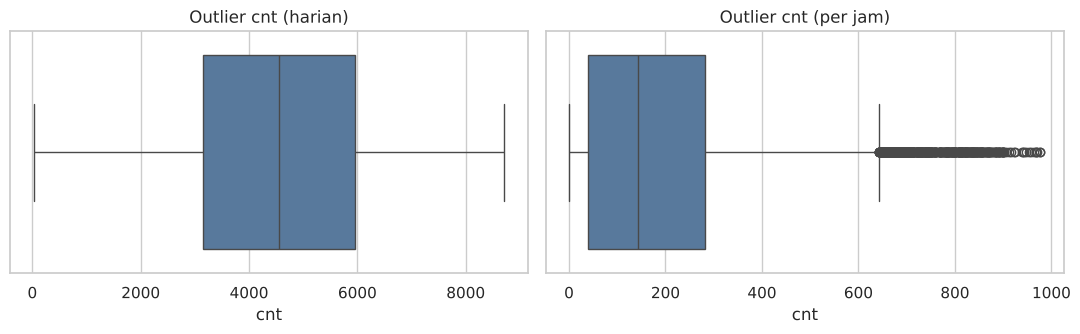

Outlier per jam (IQR): 505 baris
Outlier harian  (IQR): 0 baris


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=day_df['cnt'], ax=axes[0], color='#4C78A8'); axes[0].set_title('Outlier cnt (harian)')
sns.boxplot(x=hour_df['cnt'], ax=axes[1], color='#4C78A8'); axes[1].set_title('Outlier cnt (per jam)')
plt.tight_layout(); plt.show()

q1, q3 = hour_df['cnt'].quantile([.25, .75]); iqr = q3 - q1
print('Outlier per jam (IQR):', (hour_df['cnt'] > q3 + 1.5 * iqr).sum(), 'baris')
q1, q3 = day_df['cnt'].quantile([.25, .75]); iqr = q3 - q1
print('Outlier harian  (IQR):', ((day_df['cnt'] > q3 + 1.5 * iqr) | (day_df['cnt'] < q1 - 1.5 * iqr)).sum(), 'baris')

**Steps to Take:**
- **Inaccurate value (tipe data):** `dteday` bertipe string, ubah ke `datetime`.
- **Invalid value:** `hum == 0` pada 2011-03-10, anggap sebagai missing lalu isi dengan interpolasi linear antar hari/jam terdekat.
- **Inconsistent value:** kode numerik (season, yr, mnth, weekday, weathersit, workingday) diganti label yang bermakna; `temp`, `atemp`, `hum`, `windspeed` dikembalikan ke skala aslinya sesuai Readme.
- **Missing records:** 165 jam tidak tercatat di `hour.csv`; tidak diimputasi karena analisis memakai rata-rata per jam sehingga tidak bias.
- **Outlier:** puncak penyewaan adalah kejadian nyata (jam sibuk), jadi dipertahankan, tidak dihapus.
- Tidak ditemukan missing value maupun duplikat.

**Insight:**
- Data relatif bersih: tidak ada missing value dan duplikat, `cnt` konsisten dengan `casual + registered`.
- Masalah utama: tipe `dteday`, nilai `hum = 0` pada satu tanggal (2011-03-10), kode kategorikal, skala ternormalisasi, dan 165 jam yang tidak tercatat.

### Cleaning Data

#### Fixing inaccurate value (tipe data) dan invalid value (hum = 0)

In [7]:
for df in (day_df, hour_df):
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['hum'] = df['hum'].replace(0, np.nan)

day_df = day_df.sort_values('dteday').reset_index(drop=True)
hour_df = hour_df.sort_values('instant').reset_index(drop=True)
for df in (day_df, hour_df):
    df['hum'] = df['hum'].interpolate(method='linear')

print('hum == 0 tersisa  :', (day_df['hum'] == 0).sum(), '/', (hour_df['hum'] == 0).sum())
print('hum 2011-03-10    :', day_df.loc[day_df['dteday'] == '2011-03-10', 'hum'].round(3).values)
print('Tipe dteday       :', day_df['dteday'].dtype)

hum == 0 tersisa  : 0 / 0
hum 2011-03-10    : [0.712]
Tipe dteday       : datetime64[us]


#### Fixing inconsistent value (label kategorikal dan skala asli)

In [8]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
year_map = {0: 2011, 1: 2012}
daytype_map = {1: 'Hari Kerja', 0: 'Libur/Akhir Pekan'}

for df in (day_df, hour_df):
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['year'] = df['yr'].map(year_map)
    df['day_type'] = df['workingday'].map(daytype_map)
    df['temp_c'] = df['temp'] * 41
    df['atemp_c'] = df['atemp'] * 50
    df['hum_pct'] = df['hum'] * 100
    df['windspeed_kmh'] = df['windspeed'] * 67

hour_df[['dteday', 'hr', 'season_label', 'weather_label', 'day_type', 'temp_c', 'hum_pct', 'cnt']].head()

,dteday,hr,season_label,weather_label,day_type,temp_c,hum_pct,cnt
0,2011-01-01,0,Spring,Clear,Libur/Akhir Pekan,9.84,81.0,16
1,2011-01-01,1,Spring,Clear,Libur/Akhir Pekan,9.02,80.0,40
2,2011-01-01,2,Spring,Clear,Libur/Akhir Pekan,9.02,80.0,32
3,2011-01-01,3,Spring,Clear,Libur/Akhir Pekan,9.84,75.0,13
4,2011-01-01,4,Spring,Clear,Libur/Akhir Pekan,9.84,75.0,1


#### Menyimpan data bersih untuk dashboard

In [9]:
day_df.to_csv('dashboard/day_clean.csv', index=False)
hour_df.to_csv('dashboard/main_data.csv', index=False)
print('Tersimpan:', day_df.shape, hour_df.shape)

Tersimpan: (731, 25) (17379, 26)


**Insight:**
- `dteday` kini bertipe datetime, `hum` bernilai 0 sudah diperbaiki, dan seluruh kolom kategorikal memiliki label yang mudah dibaca.
- Suhu, kelembapan, dan kecepatan angin berada pada skala asli sehingga mudah diinterpretasikan.
- Data bersih disimpan ke folder `dashboard/` sebagai sumber data dashboard.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik

In [10]:
day_df[['cnt', 'casual', 'registered', 'temp_c', 'hum_pct', 'windspeed_kmh']].describe().round(2)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,4504.35,848.18,3656.17,20.31,62.89,12.76
std,1937.21,686.62,1560.26,7.51,14.06,5.19
min,22.00,2.00,20.00,2.42,18.79,1.50
25%,3152.00,315.50,2497.00,13.82,52.10,9.04
50%,4548.00,713.00,3662.00,20.43,62.75,12.13
75%,5956.00,1096.00,4776.50,26.87,73.02,15.63
max,8714.00,3410.00,6946.00,35.33,97.25,34.00


### Explore pola penyewaan per jam: hari kerja vs libur (Pertanyaan 1)

In [11]:
hourly_pattern = hour_df.groupby(['hr', 'day_type'])['cnt'].mean().unstack().round(1)
print(hourly_pattern.T.to_string())
print()
for col in hourly_pattern.columns:
    print(f'{col:20s}: puncak jam {hourly_pattern[col].idxmax():02d}.00 dengan rata-rata {hourly_pattern[col].max():.1f} sepeda/jam')
print('\nRata-rata per jam (keseluruhan):')
print(hour_df.groupby('day_type')['cnt'].mean().round(1))
print('\nRata-rata casual vs registered per jam:')
print(hour_df.groupby('day_type')[['casual', 'registered']].mean().round(1))

hr                   0     1     2     3    4     5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22    23
day_type                                                                                                                                                                         
Hari Kerja         36.8  16.6   8.7   4.9  5.4  24.9  102.5  290.6  477.0  241.5  135.4  158.2  200.8  198.4  183.6  201.3  293.1  525.3  492.2  348.4  249.7  186.3  138.4  88.7
Libur/Akhir Pekan  90.8  69.5  53.2  25.8  8.3   8.7   18.7   43.4  105.7  171.6  255.9  315.3  366.3  372.7  364.6  358.8  352.7  323.5  281.1  231.7  174.7  142.1  116.1  85.9

Hari Kerja          : puncak jam 17.00 dengan rata-rata 525.3 sepeda/jam
Libur/Akhir Pekan   : puncak jam 13.00 dengan rata-rata 372.7 sepeda/jam

Rata-rata per jam (keseluruhan):
day_type
Hari Kerja           193.2
Libur/Akhir Pekan    181.4
Name: cnt, dtype: float64

Rata-rata casual 

### Explore pengaruh cuaca dan musim (Pertanyaan 2)

In [12]:
weather_order = ['Clear', 'Mist/Cloudy', 'Light Snow/Rain']
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

weather_avg = day_df.groupby('weather_label')['cnt'].agg(['mean', 'count']).loc[weather_order].round(1)
weather_avg['selisih_vs_clear_%'] = ((weather_avg['mean'] / weather_avg.loc['Clear', 'mean'] - 1) * 100).round(1)
print(weather_avg, '\n')

season_avg = day_df.groupby('season_label')['cnt'].agg(['mean', 'count']).loc[season_order].round(1)
print(season_avg, '\n')

print(day_df.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='mean').loc[season_order].round(0))
print('\nRata-rata harian per tahun:')
print(day_df.groupby('year')['cnt'].mean().round(1))

                   mean  count  selisih_vs_clear_%
weather_label                                     
Clear            4876.8    463                 0.0
Mist/Cloudy      4035.9    247               -17.2
Light Snow/Rain  1803.3     21               -63.0 

                mean  count
season_label               
Spring        2604.1    181
Summer        4992.3    184
Fall          5644.3    188
Winter        4728.2    178 

weather_label   Clear  Light Snow/Rain  Mist/Cloudy
season_label                                       
Spring         2811.0            935.0       2357.0
Summer         5549.0           1169.0       4237.0
Fall           5878.0           2752.0       5222.0
Winter         5044.0           1962.0       4654.0

Rata-rata harian per tahun:
year
2011    3405.8
2012    5599.9
Name: cnt, dtype: float64


**Insight:**
- Hari kerja memiliki dua puncak tajam (sekitar jam 08.00 dan 17.00) yang mengindikasikan pola komuter; hari libur memiliki satu puncak landai di siang hari (sekitar jam 13.00).
- Pada hari libur proporsi pengguna casual jauh lebih besar dibanding hari kerja, sementara pengguna registered dominan pada hari kerja.
- Rata-rata harian turun sekitar 17% pada cuaca Mist/Cloudy dan sekitar 63% pada Light Snow/Rain dibanding cuaca Clear.
- Musim Fall tertinggi, Spring terendah; rata-rata harian 2012 jauh lebih tinggi dibanding 2011.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa penyewaan memuncak pada hari kerja dibanding hari libur?

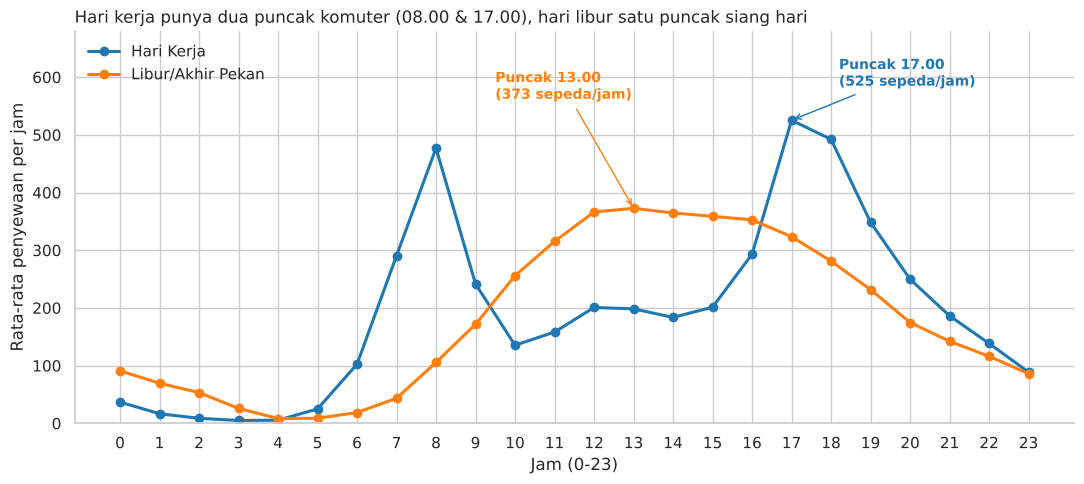

In [13]:
colors = {'Hari Kerja': '#1F77B4', 'Libur/Akhir Pekan': '#FF7F0E'}
fig, ax = plt.subplots(figsize=(11, 5))
for dt in hourly_pattern.columns:
    grp = hourly_pattern[dt]
    ax.plot(grp.index, grp.values, marker='o', linewidth=2.2, label=dt, color=colors[dt])
    pk = grp.idxmax()
    ax.annotate(f'Puncak {pk:02d}.00\n({grp.max():.0f} sepeda/jam)', xy=(pk, grp.max()),
                xytext=(pk + (1.2 if dt == 'Hari Kerja' else -3.5), grp.max() + (60 if dt == 'Hari Kerja' else 190)),
                arrowprops=dict(arrowstyle='->', color=colors[dt]), color=colors[dt], fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.set_xlabel('Jam (0-23)'); ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_title('Hari kerja punya dua puncak komuter (08.00 & 17.00), hari libur satu puncak siang hari', fontsize=12, loc='left')
ax.set_ylim(0, 680)
sns.despine(); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Pertanyaan 2: Seberapa besar cuaca dan musim memengaruhi penyewaan harian?

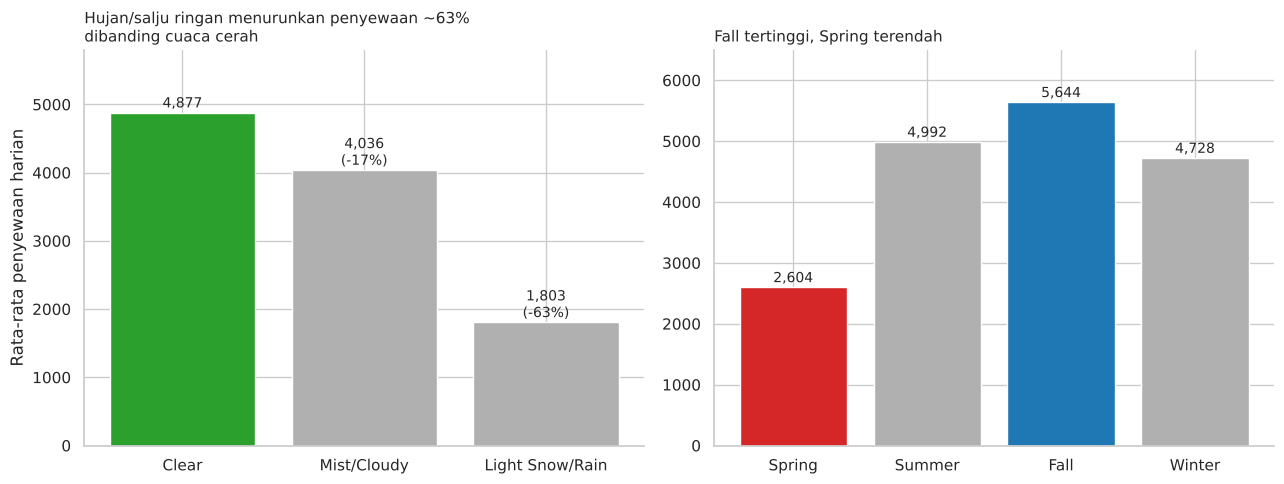

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Cuaca
w = weather_avg.reset_index()
bar_colors = ['#2CA02C' if x == 'Clear' else '#B0B0B0' for x in w['weather_label']]
b = axes[0].bar(w['weather_label'], w['mean'], color=bar_colors)
for rect, pct, lbl in zip(b, w['selisih_vs_clear_%'], w['mean']):
    txt = f'{lbl:,.0f}' if pct == 0 else f'{lbl:,.0f}\n({pct:+.0f}%)'
    axes[0].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 80, txt, ha='center', fontsize=10)
axes[0].set_title('Hujan/salju ringan menurunkan penyewaan ~63%\ndibanding cuaca cerah', fontsize=11, loc='left')
axes[0].set_ylabel('Rata-rata penyewaan harian'); axes[0].set_xlabel(''); axes[0].set_ylim(0, 5800)

# (b) Musim
s = season_avg.reset_index()
s_colors = ['#1F77B4' if x == s['mean'].max() else ('#D62728' if x == s['mean'].min() else '#B0B0B0') for x in s['mean']]
b2 = axes[1].bar(s['season_label'], s['mean'], color=s_colors)
for rect, v in zip(b2, s['mean']):
    axes[1].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 80, f'{v:,.0f}', ha='center', fontsize=10)
axes[1].set_title('Fall tertinggi, Spring terendah', fontsize=11, loc='left')
axes[1].set_ylabel(''); axes[1].set_xlabel(''); axes[1].set_ylim(0, 6500)
for a in axes: sns.despine(ax=a)
plt.tight_layout(); plt.show()

**Insight:**
- Puncak hari kerja pukul 17.00 (sekitar 525 sepeda/jam) dan pukul 08.00 (sekitar 477); puncak hari libur pukul 13.00 (sekitar 373 sepeda/jam). Selisih pada jam puncak masing-masing hari sekitar 153 sepeda/jam.
- Cuaca Clear rata-rata sekitar 4.877 sepeda/hari, Mist/Cloudy sekitar 4.036 (-17%), Light Snow/Rain sekitar 1.803 (-63%).
- Musim Fall sekitar 5.644 sepeda/hari (tertinggi), Spring sekitar 2.604 (terendah).

## Analisis Lanjutan (Opsional)

Teknik yang dipakai: **Manual Grouping & Binning** (tanpa machine learning).
- **Binning suhu** (`pd.cut`) ke kategori Dingin (<10°C), Sejuk (10-20°C), Hangat (20-30°C), Panas (>30°C) untuk melihat rentang suhu optimal penyewaan.
- **Manual grouping waktu** ke Dini Hari, Pagi Sibuk, Siang, Sore Sibuk, Malam, untuk menyederhanakan pola jam dan membandingkan hari kerja vs libur.
- **Binning tingkat permintaan harian** (`pd.qcut`) menjadi Rendah/Sedang/Tinggi untuk melihat sebaran tingkat permintaan per musim.

In [15]:
# 1. Binning suhu
day_df['temp_group'] = pd.cut(day_df['temp_c'], bins=[-np.inf, 10, 20, 30, np.inf],
                              labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (>30°C)'])
temp_summary = day_df.groupby('temp_group', observed=True)['cnt'].agg(['mean', 'count']).round(0)
print(temp_summary, '\n')

# 2. Manual grouping waktu
hour_df['time_group'] = pd.cut(hour_df['hr'], bins=[-1, 5, 9, 15, 19, 23],
                               labels=['Dini Hari (00-05)', 'Pagi Sibuk (06-09)', 'Siang (10-15)', 'Sore Sibuk (16-19)', 'Malam (20-23)'])
time_summary = hour_df.groupby(['time_group', 'day_type'], observed=True)['cnt'].mean().unstack().round(1)
print(time_summary, '\n')

# 3. Binning tingkat permintaan (tercile)
day_df['demand_level'] = pd.qcut(day_df['cnt'], q=3, labels=['Rendah', 'Sedang', 'Tinggi'])
demand_season = pd.crosstab(day_df['season_label'], day_df['demand_level'], normalize='index').loc[season_order].mul(100).round(1)
print(demand_season)

                    mean  count
temp_group                     
Dingin (<10°C)    1678.0     60
Sejuk (10-20°C)   3692.0    299
Hangat (20-30°C)  5662.0    300
Panas (>30°C)     5410.0     72 

day_type            Hari Kerja  Libur/Akhir Pekan
time_group                                       
Dini Hari (00-05)         16.4               43.0
Pagi Sibuk (06-09)       277.9               85.0
Siang (10-15)            179.7              338.9
Sore Sibuk (16-19)       414.8              297.3
Malam (20-23)            165.8              129.7 

demand_level  Rendah  Sedang  Tinggi
season_label                        
Spring          77.3    18.2     4.4
Summer          20.1    38.6    41.3
Fall             6.9    42.0    51.1
Winter          30.3    34.3    35.4


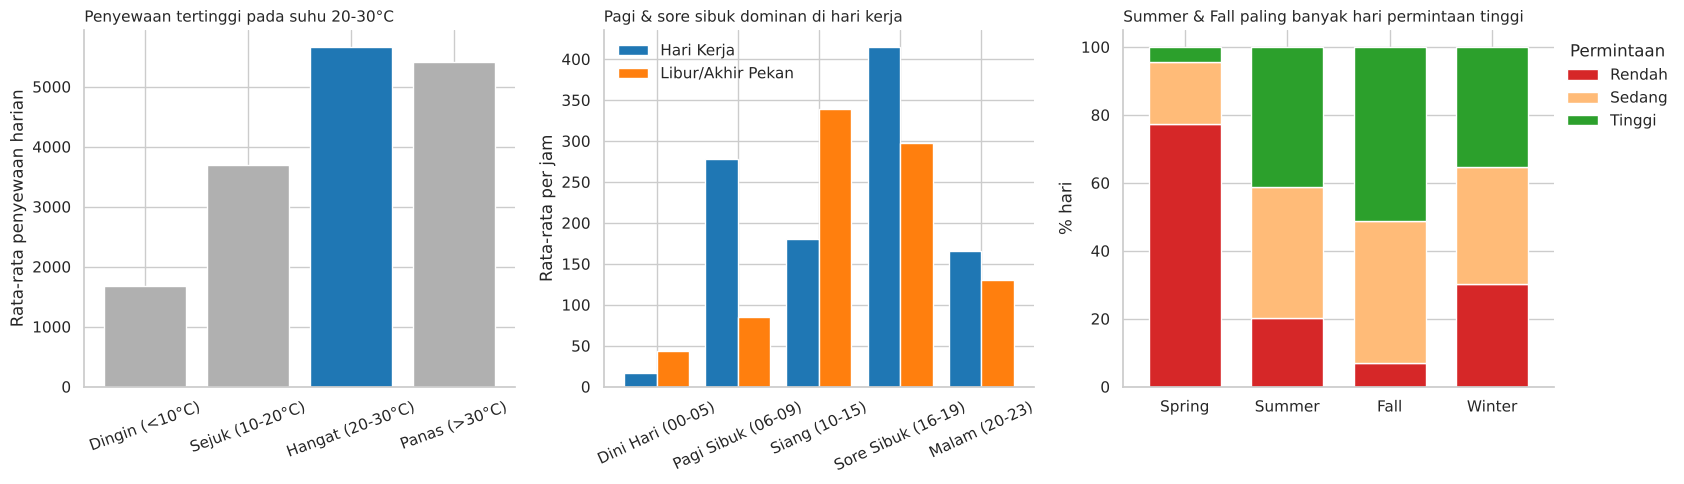

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
t = temp_summary.reset_index()
tc = ['#1F77B4' if v == t['mean'].max() else '#B0B0B0' for v in t['mean']]
axes[0].bar(t['temp_group'].astype(str), t['mean'], color=tc)
axes[0].set_title('Penyewaan tertinggi pada suhu 20-30°C', fontsize=11, loc='left'); axes[0].set_ylabel('Rata-rata penyewaan harian')
axes[0].tick_params(axis='x', rotation=20)

time_summary.plot(kind='bar', ax=axes[1], color=['#1F77B4', '#FF7F0E'], width=0.8)
axes[1].set_title('Pagi & sore sibuk dominan di hari kerja', fontsize=11, loc='left'); axes[1].set_xlabel(''); axes[1].set_ylabel('Rata-rata per jam')
axes[1].tick_params(axis='x', rotation=25); axes[1].legend(title='', frameon=False)

demand_season.plot(kind='bar', stacked=True, ax=axes[2], color=['#D62728', '#FFBB78', '#2CA02C'], width=0.7)
axes[2].set_title('Summer & Fall paling banyak hari permintaan tinggi', fontsize=11, loc='left'); axes[2].set_xlabel(''); axes[2].set_ylabel('% hari')
axes[2].tick_params(axis='x', rotation=0); axes[2].legend(title='Permintaan', frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
for a in axes: sns.despine(ax=a)
plt.tight_layout(); plt.show()

**Insight:**
- Penyewaan harian naik seiring suhu dan paling tinggi pada 20-30°C (sekitar 5.660 sepeda/hari); pada suhu >30°C sedikit menurun, pada <10°C turun tajam (sekitar 1.680).
- Rata-rata per jam pada Pagi Sibuk hari kerja (sekitar 278) jauh melampaui hari libur (sekitar 85), sedangkan pada Siang hari libur (sekitar 339) lebih tinggi dibanding hari kerja (sekitar 180).
- Hari bepermintaan tinggi terkonsentrasi pada Summer dan Fall; pada Spring hanya sekitar 4% hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Hari kerja memiliki dua puncak (pukul 08.00 sekitar 477 sepeda/jam dan pukul 17.00 sekitar 525 sepeda/jam) yang mencerminkan perjalanan komuter, sedangkan hari libur hanya satu puncak landai pukul 13.00 (sekitar 373 sepeda/jam). Pengguna registered dominan pada hari kerja, pengguna casual lebih besar porsinya pada hari libur.
- **Conclusion pertanyaan 2:** Dibanding cuaca Clear (sekitar 4.877 sepeda/hari), penyewaan turun sekitar 17% pada Mist/Cloudy dan sekitar 63% pada Light Snow/Rain. Musim Fall tertinggi (sekitar 5.644 sepeda/hari) dan Spring terendah (sekitar 2.604 sepeda/hari). Penyewaan optimal pada suhu 20-30°C.

**Rekomendasi Action Item:**
- Jadwalkan redistribusi dan pengisian sepeda di stasiun area perkantoran/transit sebelum pukul 07.00 dan 16.00 pada hari kerja; di hari libur fokuskan stok di area wisata/taman pada siang hari.
- Tawarkan promosi untuk pengguna casual pada akhir pekan siang hari untuk mendorong konversi menjadi anggota registered.
- Gunakan prakiraan cuaca untuk menyesuaikan jumlah sepeda yang disiagakan; kurangi armada operasional saat hujan/salju ringan dan manfaatkan waktu tersebut untuk perawatan.
- Jadwalkan perawatan armada besar pada musim Spring (permintaan terendah) dan siapkan kapasitas penuh pada Summer-Fall.